 # Exploration NDVI
Détection de la désertification au Niger Ce notebook explore l'évolution du NDVI (2000-2025) pour Diffa, Tillabéri et Zinder, calcule une tendance spatiale par pixel, et quantifie les surfaces de sol nu / végétation clairsemée / végétation dense entre 2016 et 2025.
 

## 1. Chargement et exploration des séries NDVI (Sentinel-2, 2016-2025)

In [1]:
# Chargement des séries NDVI mensuelles (Sentinel-2) produites par src/extract_ndvi.py :
# un fichier CSV par zone, avec le NDVI moyen du mois et le nombre d'images utilisées.
# On affiche le nombre de lignes et de valeurs manquantes (mois sans image exploitable).
import pandas as pd
import matplotlib.pyplot as plt

zones = ["diffa", "tillaberi", "zinder"]
data = {}

for zone in zones:
    df = pd.read_csv(f"../data/ndvi_{zone}.csv", parse_dates=["date"])
    data[zone] = df
    print(f"{zone}: {len(df)} lignes, {df['ndvi_mean'].isna().sum()} valeurs manquantes")

data["diffa"].head()

diffa: 120 lignes, 9 valeurs manquantes
tillaberi: 120 lignes, 5 valeurs manquantes
zinder: 120 lignes, 3 valeurs manquantes


,date,ndvi_mean,n_images
0,2016-01-01,0.171220,4
1,2016-02-01,0.153239,4
2,2016-03-01,NaN,0
3,2016-04-01,0.145945,8
4,2016-05-01,0.123627,4


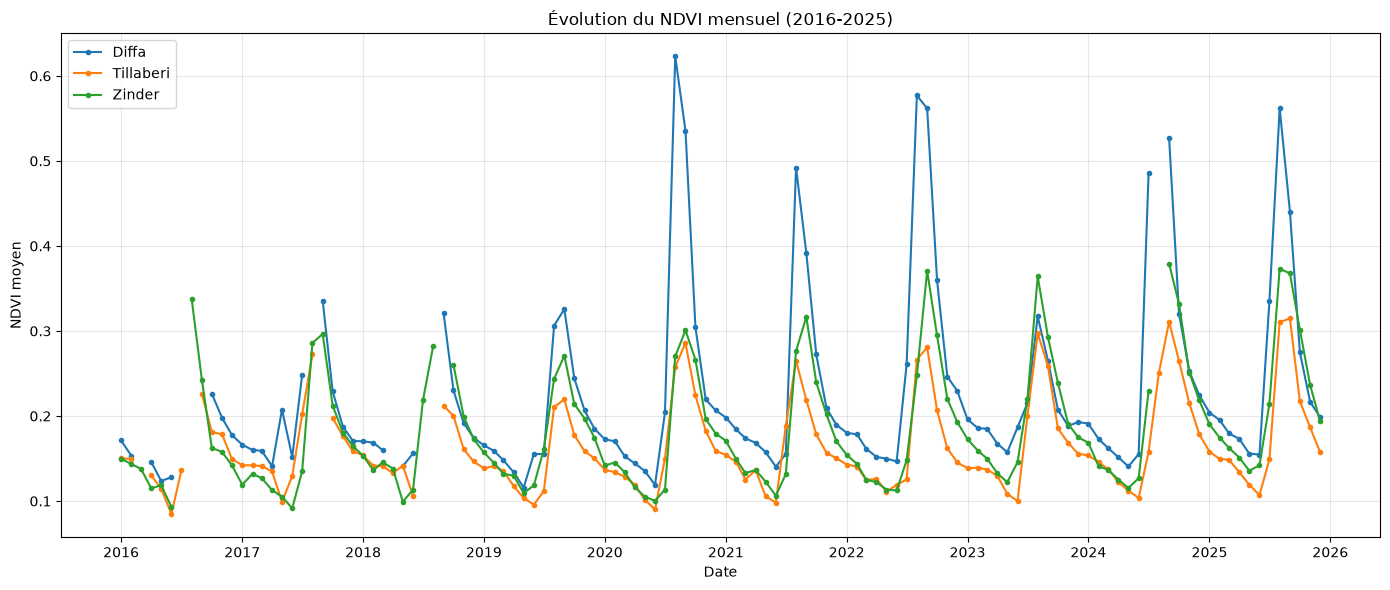

In [2]:
# Figure 1 : évolution du NDVI mensuel des trois zones (2016-2025).
# On y lit le cycle saisonnier : pic en fin de saison des pluies, creux en saison sèche.
# Le graphique est sauvegardé dans outputs/. Les lignes commentées plus bas sont un essai
# de mise en forme de l'axe des dates, non utilisé.
fig, ax = plt.subplots(figsize=(14, 6))

for zone in zones:
    df = data[zone]
    ax.plot(df["date"], df["ndvi_mean"], marker="o", markersize=3, label=zone.capitalize())

ax.set_title("Évolution du NDVI mensuel (2016-2025)")
ax.set_xlabel("Date")
ax.set_ylabel("NDVI moyen")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/ndvi_evolution_2016_2025.png", dpi=150)


#import matplotlib.dates as mdates

#ax = plt.gca()

#
#ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
#ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))

#plt.xticks(rotation=45, ha='right')
#plt.tight_layout()

plt.show()

Diffa: pente = +0.0301 NDVI/an (hausse)
Tillaberi: pente = +0.0100 NDVI/an (hausse)
Zinder: pente = +0.0098 NDVI/an (hausse)


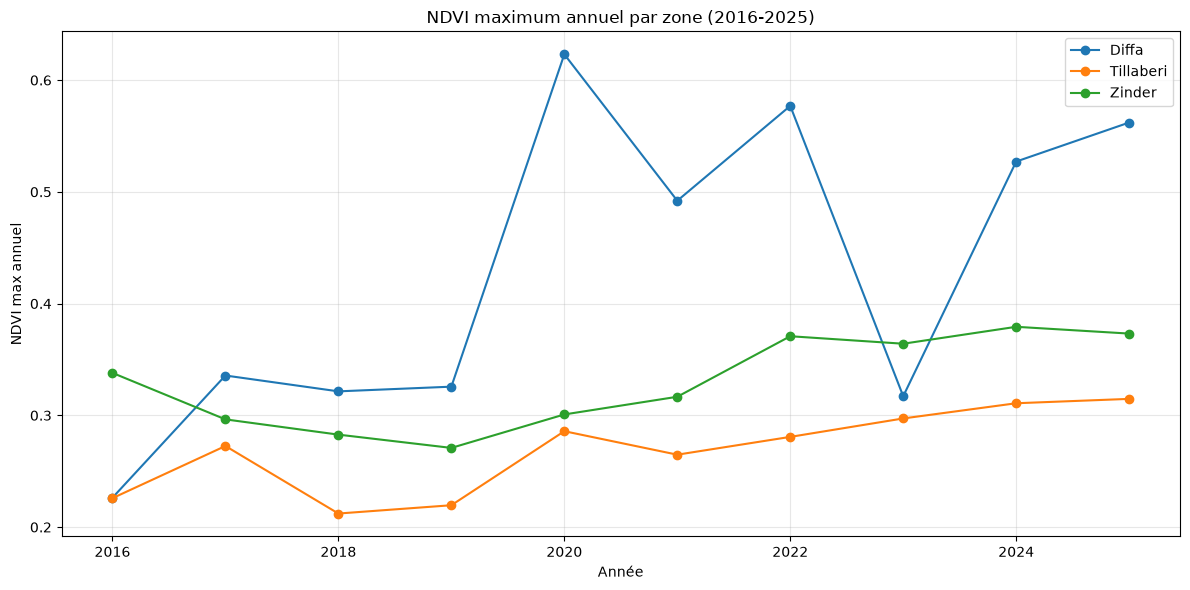

In [3]:
# Figure 2 : NDVI maximum annuel par zone, qui élimine le cycle saisonnier.
# Pente positive = reverdissement sur 2016-2025.
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6))

annual_max = {}
for zone in zones:
    df = data[zone].copy()
    df["year"] = df["date"].dt.year
    yearly = df.groupby("year")["ndvi_mean"].max()
    annual_max[zone] = yearly
    ax.plot(yearly.index, yearly.values, marker="o", label=zone.capitalize())

    # Tendance linéaire (régression simple) pour visualiser la pente sur 10 ans
    coeffs = np.polyfit(yearly.index, yearly.values, 1)
    print(f"{zone.capitalize()}: pente = {coeffs[0]:+.4f} NDVI/an "
          f"({'baisse' if coeffs[0] < 0 else 'hausse'})")

ax.set_title("NDVI maximum annuel par zone (2016-2025)")
ax.set_xlabel("Année")
ax.set_ylabel("NDVI max annuel")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/ndvi_max_annuel_2016_2025.png", dpi=150)
plt.show()

## 2. Connexion à Earth Engine et tendance du NDVI par pixel

In [4]:
# Connexion à Google Earth Engine (projet Google Cloud « desertification-niger »).
# ZONES : emprises rectangulaires [lon_min, lat_min, lon_max, lat_max] des trois zones d'étude


import ee
ee.Initialize(project="desertification-niger")

ZONES = {
    "Diffa": ee.Geometry.Rectangle([12.8, 13.0, 13.5, 13.6]),
    "Tillaberi": ee.Geometry.Rectangle([0.9, 14.0, 1.6, 14.6]),
    "Zinder": ee.Geometry.Rectangle([8.7, 13.5, 9.4, 14.1]),
}

def mask_clouds_s2(image):
    scl = image.select("SCL")
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.updateMask(mask)

def add_ndvi(image):
    ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")
    return image.addBands(ndvi)

In [5]:
# compute_trend : pente du NDVI par pixel (régression linéaire, 2016-2025).
# Pour chaque année : image du NDVI maximum + une bande « year » (la valeur de l'année dans chaque pixel).


def compute_trend(zone_geom, start_year=2016, end_year=2025):
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(zone_geom)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_clouds_s2)
        .map(add_ndvi)
    )

    def annual_image(year):
        year = ee.Number(year)
        start = ee.Date.fromYMD(year, 1, 1)
        end = ee.Date.fromYMD(year, 12, 31)
        ndvi_max = collection.filterDate(start, end).select("NDVI").max()
        # .float() : évite l'erreur « homogeneous image collection »
        return ndvi_max.addBands(ee.Image.constant(year).rename("year").float()).set("year", year)

    years = ee.List.sequence(start_year, end_year)
    annual_imgs = ee.ImageCollection(years.map(annual_image))

    trend = annual_imgs.select(["year", "NDVI"]).reduce(ee.Reducer.linearFit())
    return trend.select("scale").clip(zone_geom)

In [6]:
# Carte de tendance de Diffa : rouge = le NDVI baisse, jaune = stable, vert = le NDVI augmente
# (échelle de -0,05 à +0,05 NDVI par an). L'image est calculée par Earth Engine puis affichée via une URL.
#Carte de tendance pour Diffa
from IPython.display import Image, display

zone_name = "Diffa"
slope_img = compute_trend(ZONES[zone_name])

vis_params = {
    "min": -0.05, "max": 0.05,
    "palette": ["d73027", "fee08b", "1a9850"],
}

url = slope_img.getThumbURL({**vis_params, "region": ZONES[zone_name], "dimensions": 600})
display(Image(url=url))

## 3. Altitude (SRTM)

In [7]:
# Altitude (SRTM, 90 m) : minimum, maximum et moyenne de chaque zone, pour situer le relief
# (Diffa et Tillabéri : relief bas ; Zinder : plateau plus élevé).
dem = ee.Image("USGS/SRTMGL1_003")
zones = ["diffa", "tillaberi", "zinder"]

for zone in zones:
    zone_name = zone.capitalize()
    stats = dem.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=ZONES[zone_name],
        scale=90,
        maxPixels=1e9,
    ).getInfo()
    print(f"{zone_name}: altitude min={stats['elevation_min']}m, "
          f"max={stats['elevation_max']}m, moyenne={stats['elevation_mean']:.1f}m")

Diffa: altitude min=267m, max=317m, moyenne=295.5m
Tillaberi: altitude min=188m, max=334m, moyenne=243.8m
Zinder: altitude min=375m, max=655m, moyenne=451.3m


## 4. Extension historique avec Landsat (2000-2015)

In [8]:
# Fonctions Landsat (2000-2015), équivalentes à celles de Sentinel-2 mais avec d'autres bandes 
# - mask_clouds_landsat : retire nuages et ombres via la bande QA_PIXEL ;
# - scale_landsat_sr : convertit les valeurs brutes en réflectance (facteur 0,0000275, décalage -0,2) ;
# - add_ndvi_l57 / add_ndvi_l89 : NDVI avec les bonnes bandes (la numérotation change entre Landsat 5/7 et 8) ;
# - get_landsat_collection : fusionne Landsat 5, 7 et 8 en une seule collection
def mask_clouds_landsat(image):
    qa = image.select("QA_PIXEL")
    cloud_bit = 1 << 3
    shadow_bit = 1 << 4
    mask = qa.bitwiseAnd(cloud_bit).eq(0).And(qa.bitwiseAnd(shadow_bit).eq(0))
    return image.updateMask(mask)

def scale_landsat_sr(image):
    optical = image.select("SR_B.").multiply(0.0000275).add(-0.2)
    return image.addBands(optical, None, True)

def add_ndvi_l57(image):  # Landsat 5 & 7 : rouge=SR_B3, PIR=SR_B4
    ndvi = image.normalizedDifference(["SR_B4", "SR_B3"]).rename("NDVI")
    return image.addBands(ndvi)

def add_ndvi_l89(image):  # Landsat 8 & 9 : rouge=SR_B4, PIR=SR_B5
    ndvi = image.normalizedDifference(["SR_B5", "SR_B4"]).rename("NDVI")
    return image.addBands(ndvi)

def get_landsat_collection(zone_geom, start, end):
    l5 = (ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
          .filterBounds(zone_geom).filterDate(start, end)
          .map(mask_clouds_landsat).map(scale_landsat_sr).map(add_ndvi_l57))
    l7 = (ee.ImageCollection("LANDSAT/LE07/C02/T1_L2")
          .filterBounds(zone_geom).filterDate(start, end)
          .map(mask_clouds_landsat).map(scale_landsat_sr).map(add_ndvi_l57))
    l8 = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
          .filterBounds(zone_geom).filterDate(start, end)
          .map(mask_clouds_landsat).map(scale_landsat_sr).map(add_ndvi_l89))
    return l5.merge(l7).merge(l8)

In [9]:
# Extraction du NDVI maximum annuel Landsat (2000-2015) : pour chaque zone et chaque année
# moyenne spatiale du NDVI maximum de l'année
# Cellule longue (16 ans x 3 zones)
landsat_annual_max = {}

for zone in zones:
    zone_name = zone.capitalize()
    coll = get_landsat_collection(ZONES[zone_name], "2000-01-01", "2015-12-31")
    records = []
    for year in range(2000, 2016):
        yearly = coll.filterDate(f"{year}-01-01", f"{year}-12-31").select("NDVI").max()
        stats = yearly.reduceRegion(
            reducer=ee.Reducer.mean(), geometry=ZONES[zone_name], scale=30, maxPixels=1e9
        )
        val = stats.get("NDVI").getInfo()
        records.append({"year": year, "ndvi_max": val})
        print(f"{zone_name} {year}: {val}")
    landsat_annual_max[zone] = pd.DataFrame(records)
    landsat_annual_max[zone].to_csv(f"../data/ndvi_landsat_annual_{zone}.csv", index=False)

Diffa 2000: 0.31115824301345135
Diffa 2001: 0.25671949453941434
Diffa 2002: 0.3245204920475243
Diffa 2003: 0.313354731520007
Diffa 2004: 0.2853440378381506
Diffa 2005: 0.32701451520386543
Diffa 2006: 0.21317143322549426
Diffa 2007: 0.3714917043117509
Diffa 2008: 0.33036748047502057
Diffa 2009: 0.34665435267554195
Diffa 2010: 0.28824666036415436
Diffa 2011: 0.2483801140428539
Diffa 2012: 0.37531231187172365
Diffa 2013: 0.5968897293508558
Diffa 2014: 0.5315425708129053
Diffa 2015: 0.5021854970973104
Tillaberi 2000: 0.240566482467022
Tillaberi 2001: 0.252462078893082
Tillaberi 2002: 0.220015456958751
Tillaberi 2003: 0.17016772382030082
Tillaberi 2004: 0.19094306931542168
Tillaberi 2005: 0.1827063896713836
Tillaberi 2006: 0.19374174692864757
Tillaberi 2007: 0.2970615235264974
Tillaberi 2008: 0.20230401628142625
Tillaberi 2009: 0.21687319482444184
Tillaberi 2010: 0.1889529281942797
Tillaberi 2011: 0.15201074198757528
Tillaberi 2012: 0.2023558169490396
Tillaberi 2013: 0.26687750802234494
Til

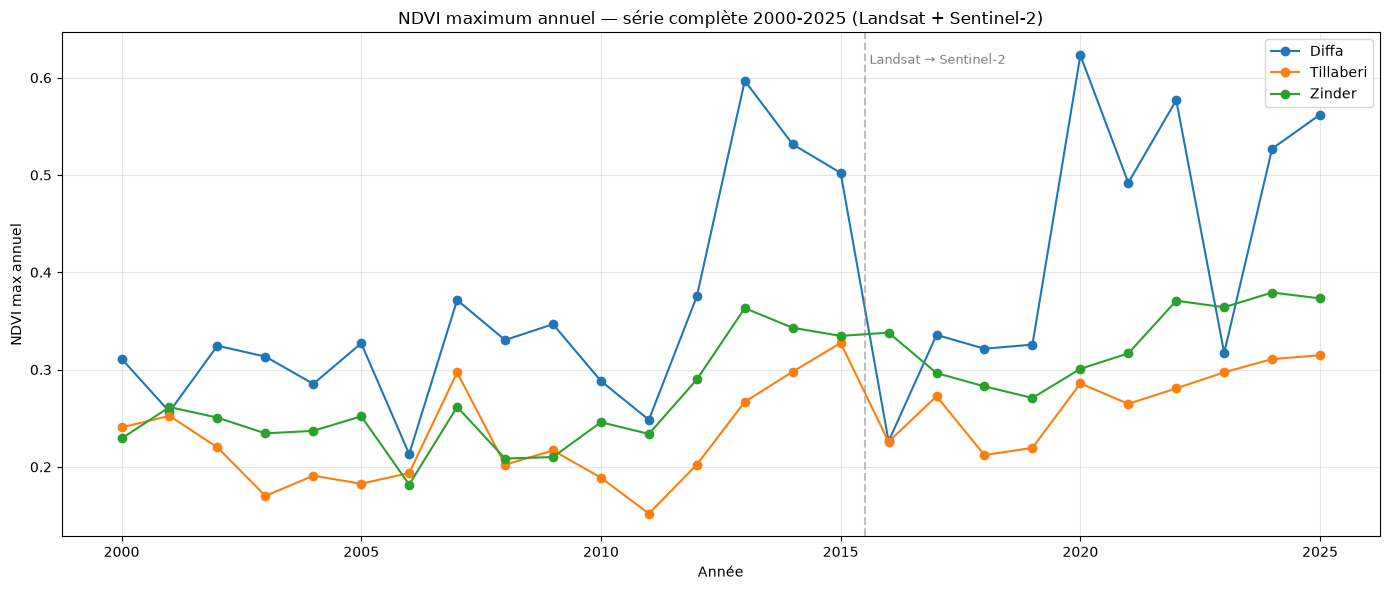

In [10]:
# Figure 3 : série complète 2000-2025 en raccordant Landsat (2000-2015) et Sentinel-2 (2016-2025).
# La ligne pointillée marque le changement de capteur : la rupture visible en 2016 est probablement
# d'origine méthodologique (résolution 30 m -> 10 m,
# pas une vraie baisse de végétation
fig, ax = plt.subplots(figsize=(14, 6))

full_series = {}
for zone in zones:
    # Série Landsat (2000-2015)
    landsat_df = landsat_annual_max[zone].rename(columns={"ndvi_max": "ndvi"})

    # Série Sentinel-2 : NDVI max par an, à partir des données mensuelles déjà chargées
    s2_df = data[zone].copy()
    s2_df["year"] = s2_df["date"].dt.year
    s2_annual = s2_df.groupby("year")["ndvi_mean"].max().reset_index()
    s2_annual = s2_annual.rename(columns={"ndvi_mean": "ndvi"})

    combined = pd.concat([landsat_df, s2_annual], ignore_index=True).sort_values("year")
    combined["source"] = combined["year"].apply(lambda y: "Landsat" if y <= 2015 else "Sentinel-2")
    full_series[zone] = combined
    combined.to_csv(f"../data/ndvi_full_series_{zone}.csv", index=False)

    ax.plot(combined["year"], combined["ndvi"], marker="o", label=zone.capitalize())

ax.axvline(2015.5, color="gray", linestyle="--", alpha=0.5)
ax.text(2015.6, ax.get_ylim()[1]*0.95, "Landsat → Sentinel-2", fontsize=9, color="gray")
ax.set_title("NDVI maximum annuel — série complète 2000-2025 (Landsat + Sentinel-2)")
ax.set_xlabel("Année")
ax.set_ylabel("NDVI max annuel")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/ndvi_full_series_2000_2025.png", dpi=150)
plt.show()

In [11]:
# Cartes de tendance pour Tillabéri et Zinder (même principe que pour Diffa, section 2)
# Les taches rouges sont des foyers locaux de dégradation, invisibles dans la moyenne de la zone
for zone_name in ["Tillaberi", "Zinder"]:
    print(f"Calcul de la tendance pour {zone_name}...")
    slope_img = compute_trend(ZONES[zone_name])

    vis_params = {
        "min": -0.05, "max": 0.05,
        "palette": ["d73027", "fee08b", "1a9850"],
    }

    url = slope_img.getThumbURL({**vis_params, "region": ZONES[zone_name], "dimensions": 600})
    print(f"URL {zone_name}: {url}")
    display(Image(url=url))

Calcul de la tendance pour Tillaberi...
URL Tillaberi: https://earthengine.googleapis.com/v1/projects/desertification-niger/thumbnails/15784686b562ea9059f435f6190c7d5e-b359a3153f12d0e1bb2b8af3eb5c946f:getPixels


Calcul de la tendance pour Zinder...
URL Zinder: https://earthengine.googleapis.com/v1/projects/desertification-niger/thumbnails/dc7c237854bc1b023b52b713d323b7e0-93b669cf3a1f9dab8e97c07baa2b303b:getPixels


## 5. Classification par seuillage du NDVI (méthode de référence)

In [12]:
# Classification par seuillage du NDVI : règle fixe, sans apprentissage 
# - get_ndvi_composite : NDVI médian de l'année (réduit le bruit des nuages résiduels) ;
# - classify_ndvi : 0 = sol nu (NDVI < 0,15), 1 = clairsemé (0,15 à 0,30), 2 = dense (>= 0,30) ;
# - compute_class_areas_km2 : surface de chaque classe en km² (aire des pixels).
#   tileScale=4 évite l'erreur Earth Engine « User memory limit exceeded ».
def get_ndvi_composite(zone_geom, year):
    """NDVI médian sur l'année (composite annuel, réduit le bruit)."""
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(zone_geom)
        .filterDate(f"{year}-01-01", f"{year}-12-31")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_clouds_s2)
        .map(add_ndvi)
    )
    return collection.select("NDVI").median().clip(zone_geom)

def classify_ndvi(ndvi_img):
    """0 = sol nu, 1 = végétation clairsemée, 2 = végétation dense."""
    bare = ndvi_img.lt(0.15)
    sparse = ndvi_img.gte(0.15).And(ndvi_img.lt(0.30))
    dense = ndvi_img.gte(0.30)
    return bare.multiply(0).add(sparse.multiply(1)).add(dense.multiply(2)).rename("classe")

def compute_class_areas_km2(classified_img, zone_geom, scale=30):
    """Retourne un dict {classe: surface_km2}."""
    pixel_area = ee.Image.pixelArea().divide(1e6)  # m² -> km²
    areas = {}
    for cls, name in [(0, "sol_nu"), (1, "veg_clairsemee"), (2, "veg_dense")]:
        mask = classified_img.eq(cls)
        area_img = pixel_area.updateMask(mask)
        stats = area_img.reduceRegion(
            reducer=ee.Reducer.sum(), geometry=zone_geom,
            scale=scale, maxPixels=1e9, tileScale=4,   # tileScale : évite « User memory limit exceeded »
        )
        areas[name] = stats.get("area").getInfo()
    return areas

In [13]:
# Application du seuillage aux trois zones pour 2016 et 2025, puis sauvegarde des surfaces dans
# data/classification_areas_2016_2025.csv
# 2016 repose sur beaucoup moins d'images que 2025
# (par exemple 4 images en janvier 2016 contre 24 en janvier 2024 pour Diffa).
results = []

for zone in zones:
    zone_name = zone.capitalize()
    print(f"Traitement {zone_name}...")

    for year in [2016, 2025]:
        ndvi_img = get_ndvi_composite(ZONES[zone_name], year)
        classified = classify_ndvi(ndvi_img)
        
        areas = compute_class_areas_km2(classified, ZONES[zone_name])
        areas["zone"] = zone_name
        areas["year"] = year
        results.append(areas)
        print(f"  {year}: sol_nu={areas['sol_nu']:.1f} km², "
              f"clairsemee={areas['veg_clairsemee']:.1f} km², "
              f"dense={areas['veg_dense']:.1f} km²")

df_areas = pd.DataFrame(results)
df_areas.to_csv("../data/classification_areas_2016_2025.csv", index=False)
df_areas

Traitement Diffa...
  2016: sol_nu=2025.4 km², clairsemee=2814.7 km², dense=194.6 km²
  2025: sol_nu=878.8 km², clairsemee=3593.6 km², dense=562.3 km²
Traitement Tillaberi...
  2016: sol_nu=2236.2 km², clairsemee=2585.7 km², dense=191.9 km²
  2025: sol_nu=2201.8 km², clairsemee=2603.4 km², dense=208.5 km²
Traitement Zinder...
  2016: sol_nu=3293.1 km², clairsemee=1704.1 km², dense=27.2 km²
  2025: sol_nu=675.5 km², clairsemee=4296.2 km², dense=52.7 km²


,sol_nu,veg_clairsemee,veg_dense,zone,year
0,2025.416825,2814.685483,194.623955,Diffa,2016
1,878.763174,3593.618801,562.344288,Diffa,2025
2,2236.159196,2585.682466,191.883051,Tillaberi,2016
3,2201.795099,2603.417324,208.512290,Tillaberi,2025
4,3293.136473,1704.052757,27.225678,Zinder,2016
5,675.496800,4296.168397,52.749711,Zinder,2025


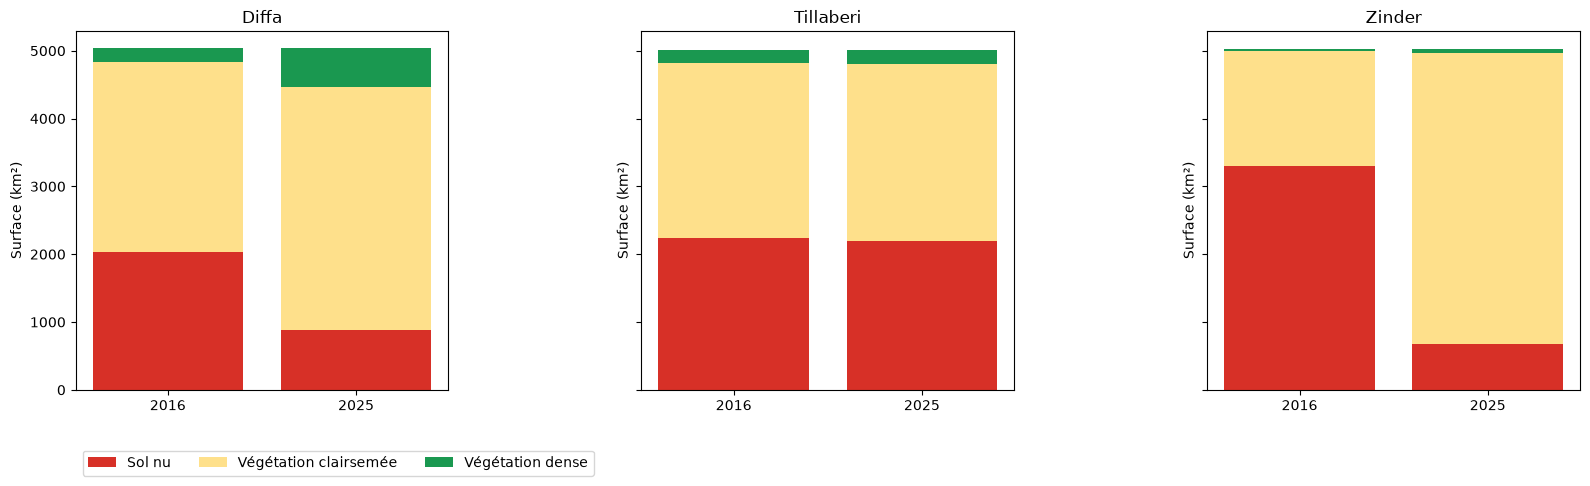

In [14]:
# Barres empilées surfaces sol nu / clairsemé / dense, 2016 vs 2025, pour chaque zone
# Sauvegardé dans outputs/classification_comparaison_2016_2025.png
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, zone_name in zip(axes, ["Diffa", "Tillaberi", "Zinder"]):
    sub = df_areas[df_areas["zone"] == zone_name]
    x = ["2016", "2025"]
    bottom = [0, 0]
    for cls, color, label in [("sol_nu", "#d73027", "Sol nu"),
                                ("veg_clairsemee", "#fee08b", "Végétation clairsemée"),
                                ("veg_dense", "#1a9850", "Végétation dense")]:
        vals = sub[cls].values
        ax.bar(x, vals, bottom=bottom, color=color, label=label if zone_name == "Diffa" else "")
        bottom = [b + v for b, v in zip(bottom, vals)]
    ax.set_title(zone_name)
    ax.set_ylabel("Surface (km²)")

axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=3)
plt.tight_layout()
plt.savefig("../outputs/classification_comparaison_2016_2025.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Carte interactive (optionnelle)

In [15]:
# Carte interactive : tendance NDVI de Diffa sur un fond OpenStreetMap, pour nommer les lieux en zoomant
import geemap

zone_name = "Diffa"
slope_img = compute_trend(ZONES[zone_name])

vis_params = {
    "min": -0.05, "max": 0.05,
    "palette": ["d73027", "fee08b", "1a9850"],
}

Map = geemap.Map(center=[13.3, 13.1], zoom=9)
Map.addLayer(slope_img, vis_params, f"Tendance NDVI {zone_name}")
Map.addLayer(ZONES[zone_name], {}, "Emprise étudiée", False)
Map

Map(center=[13.3, 13.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

## 7. Classification K-means (apprentissage non supervisé, approche exploratoire)

K-means regroupe les pixels en 3 classes spectrales sans étiquettes. Ses classes sont relatives à chaque zone et ne sont pas validées par des données de terrain.

In [16]:
# K-means regroupe les pixels en 3 classes spectrales, sans étiquettes.
# Variables par pixel : B2, B3, B4, B8 et NDVI (composite médian de l'année), sans mise à l'échelle explicite
# Entraînement sur 1 500 pixels (résolution 60 m, graine 42), puis application à toute la zone
# La fonction renvoie l'image des clusters et le NDVI moyen de chaque cluster (calculé sur l'échantillon) 
# K-means numérote ses groupes sans les nommer, c'est ce NDVI moyen qui permet de les interpréter.
def classify_kmeans(zone_geom, year, n_clusters=3, n_samples=1500):
    """
    Classification K-means allégée.
    - Réduit n_samples
    - Utilise scale=60 (au lieu de 30) pour l'échantillonnage
    - Calcule le NDVI moyen par cluster sur l'échantillon uniquement
    """
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(zone_geom)
        .filterDate(f"{year}-01-01", f"{year}-12-31")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_clouds_s2)
        .map(add_ndvi)
    )
    composite = collection.median().clip(zone_geom)
    features_img = composite.select(["B2", "B3", "B4", "B8", "NDVI"])

    # Échantillonnage allégé : scale=60, n_samples=1500
    training = features_img.sample(
        region=zone_geom, scale=60, numPixels=n_samples,
        seed=42, geometries=False, tileScale=4
    )

    clusterer = ee.Clusterer.wekaKMeans(n_clusters).train(training)
    clustered = features_img.cluster(clusterer)

    # NDVI moyen sur l'échantillon uniquement
    labeled_samples = training.cluster(clusterer)
    ndvi_by_cluster = labeled_samples.reduceColumns(
        reducer=ee.Reducer.mean().group(groupField=1, groupName="cluster"),
        selectors=["NDVI", "cluster"]
    )

    return clustered, ndvi_by_cluster.getInfo()

In [17]:
# K-means sur Diffa en 2025 : on affiche le NDVI moyen de chacun des 3 clusters.
# Un modèle est entraîné séparément pour chaque zone; les classes sont donc relatives à la zone.
print("=== Diffa 2025 ===")
clustered_diffa, info_diffa = classify_kmeans(ZONES["Diffa"], 2025)
print(info_diffa)

=== Diffa 2025 ===
{'groups': [{'cluster': 0, 'mean': 0.19339746378716968}, {'cluster': 1, 'mean': 0.3603159588613735}, {'cluster': 2, 'mean': 0.16741238388429708}]}


In [18]:
# K-means sur Tillabéri en 2025 : NDVI moyen de chacun des 3 clusters.
print("=== Tillaberi 2025 ===")
clustered_tilla, info_tilla = classify_kmeans(ZONES["Tillaberi"], 2025)
print(info_tilla)

=== Tillaberi 2025 ===
{'groups': [{'cluster': 0, 'mean': 0.1628173565816565}, {'cluster': 1, 'mean': 0.13434348459935413}, {'cluster': 2, 'mean': 0.19226252010834594}]}


In [19]:
# K-means sur Zinder en 2025 : NDVI moyen de chacun des 3 clusters.
print("=== Zinder 2025 ===")
clustered_zinder, info_zinder = classify_kmeans(ZONES["Zinder"], 2025)
print(info_zinder)

=== Zinder 2025 ===
{'groups': [{'cluster': 0, 'mean': 0.16243481657381625}, {'cluster': 1, 'mean': 0.1840734576433897}, {'cluster': 2, 'mean': 0.2034428062114289}]}


In [20]:
# Cartes K-means. Les clusters sont renumérotés du NDVI le plus bas au plus haut
# (0 = sol nu, 1 = clairsemé, 2 = dense).
# remap_orders est saisi à la main, il doit être identique à l'ordre calculé dans la cellule
# de vérification située plus bas (celle qui compare « clusters du NDVI le plus bas au plus haut »).
from IPython.display import Image, display

# Pour chaque zone : ordre de remapping des clusters (du NDVI le plus bas au plus haut)
# Basé sur les résultats obtenus
remap_orders = {
    "Diffa":     [2, 0, 1],   # [sol nu, clairsemé, dense]
    "Tillaberi": [1, 0, 2],
    "Zinder":    [0, 1, 2],
}

results_kmeans = {
    "Diffa":     clustered_diffa,
    "Tillaberi": clustered_tilla,
    "Zinder":    clustered_zinder,
}

vis_params = {
    "min": 0, "max": 2,
    "palette": ["#d73027", "#fee08b", "#1a9850"]   # rouge=sol nu, jaune=clairsemé, vert=dense
}

for zone_name in ["Diffa", "Tillaberi", "Zinder"]:
    print(f"\n--- Carte K-means — {zone_name} 2025 ---")
    clustered_img = results_kmeans[zone_name]
    # Remapper les clusters : ancien numéro → nouveau numéro (0=sol nu, 1=clairsemé, 2=dense)
    remapped = clustered_img.remap(remap_orders[zone_name], [0, 1, 2]).rename("classe")
    url = remapped.getThumbURL({
        **vis_params,
        "region": ZONES[zone_name],
        "dimensions": 800,
        "format": "png"
    })
    display(Image(url=url))


--- Carte K-means — Diffa 2025 ---



--- Carte K-means — Tillaberi 2025 ---



--- Carte K-means — Zinder 2025 ---


In [21]:
# Surfaces (km²) des 3 classes K-means en 2025, calculées à 60 m de résolution (le seuillage utilise 30 m) 
# les deux méthodes ne sont donc pas directement comparables
# Résultat sauvegardé dans data/classification_kmeans_2025.csv
def quantify_remapped(clustered_img, remap_order, zone_geom, scale=60):
    """Quantifie les surfaces en km² après remapping des clusters."""
    remapped = clustered_img.remap(remap_order, [0, 1, 2]).rename("classe")
    pixel_area = ee.Image.pixelArea().divide(1e6)
    img = pixel_area.addBands(remapped)
    res = img.reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName="classe"),
        geometry=zone_geom, scale=scale, maxPixels=1e10, tileScale=8
    ).getInfo()
    areas = {int(g["classe"]): g["sum"] for g in res["groups"]}
    return {
        "sol_nu": areas.get(0, 0),
        "veg_clairsemee": areas.get(1, 0),
        "veg_dense": areas.get(2, 0),
    }

rows = []
for zone_name in ["Diffa", "Tillaberi", "Zinder"]:
    print(f"Quantification {zone_name}...")
    areas = quantify_remapped(results_kmeans[zone_name], remap_orders[zone_name], ZONES[zone_name])
    areas["zone"] = zone_name
    areas["year"] = 2025
    rows.append(areas)
    print(f"  sol nu={areas['sol_nu']:.1f} km², "
          f"clairsemée={areas['veg_clairsemee']:.1f} km², "
          f"dense={areas['veg_dense']:.1f} km²")

df_kmeans = pd.DataFrame(rows)
df_kmeans.to_csv("../data/classification_kmeans_2025.csv", index=False)
df_kmeans

Quantification Diffa...
  sol nu=2876.9 km², clairsemée=1425.4 km², dense=732.1 km²
Quantification Tillaberi...
  sol nu=1792.3 km², clairsemée=2351.9 km², dense=869.7 km²
Quantification Zinder...
  sol nu=1482.4 km², clairsemée=2743.8 km², dense=798.5 km²


,sol_nu,veg_clairsemee,veg_dense,zone,year
0,2876.895816,1425.366830,732.108032,Diffa,2025
1,1792.305736,2351.885911,869.735667,Tillaberi,2025
2,1482.364842,2743.800606,798.479553,Zinder,2025


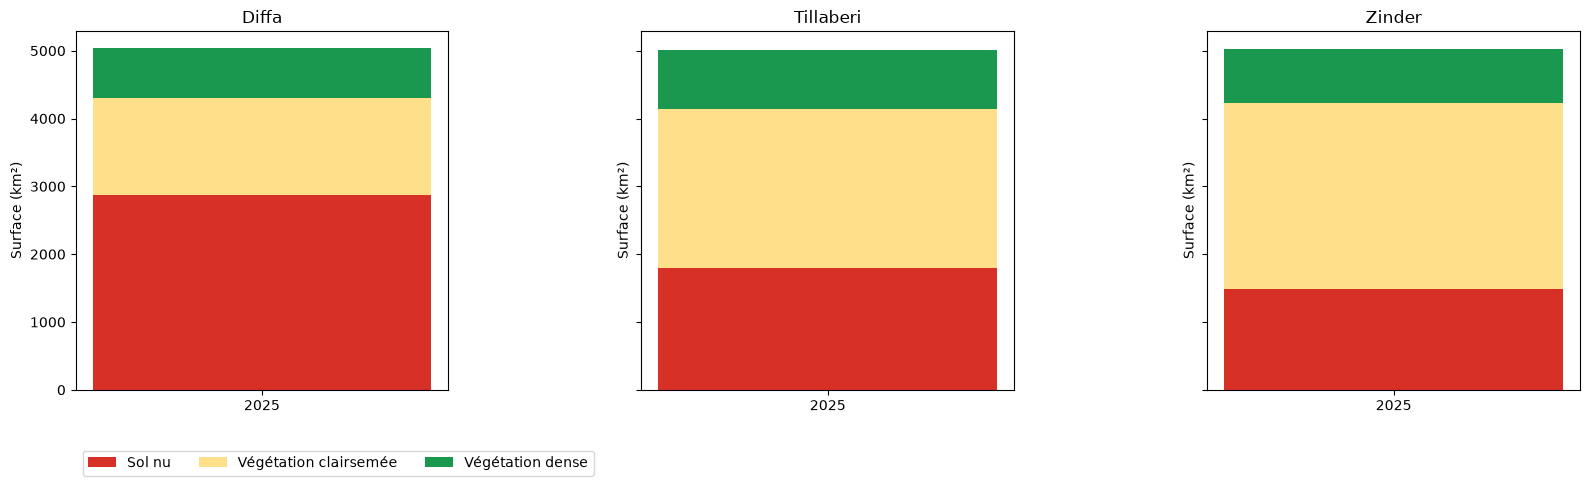

In [22]:
# Barres empilées des surfaces K-means 2025 par zone (sauvegardé dans outputs/classification_kmeans_2025.png).
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, zone_name in zip(axes, ["Diffa", "Tillaberi", "Zinder"]):
    sub = df_kmeans[df_kmeans["zone"] == zone_name]
    bottom = 0
    for cls, color, label in [("sol_nu", "#d73027", "Sol nu"),
                              ("veg_clairsemee", "#fee08b", "Végétation clairsemée"),
                              ("veg_dense", "#1a9850", "Végétation dense")]:
        val = sub[cls].values[0]
        ax.bar(["2025"], [val], bottom=bottom, color=color,
               label=label if zone_name == "Diffa" else "")
        bottom += val
    ax.set_title(zone_name)
    ax.set_ylabel("Surface (km²)")

axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=3)
plt.tight_layout()
plt.savefig("../outputs/classification_kmeans_2025.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# Vérification pour chaque zone, l'ordre des clusters calculé à partir des NDVI moyens doit être
# identique à remap_orders. Sinon, les cartes et les surfaces K-means seront mal étiquetées.
for nom, info in [("Diffa", info_diffa), ("Tillaberi", info_tilla), ("Zinder", info_zinder)]:
    groupes = sorted(info["groups"], key=lambda g: g["mean"])
    ordre = [int(g["cluster"]) for g in groupes]
    print(nom,
          "| clusters du NDVI le plus bas au plus haut :", ordre,
          "| NDVI moyens :", [round(g["mean"], 3) for g in groupes],
          "| remap_orders actuel :", remap_orders[nom])

Diffa | clusters du NDVI le plus bas au plus haut : [2, 0, 1] | NDVI moyens : [0.167, 0.193, 0.36] | remap_orders actuel : [2, 0, 1]
Tillaberi | clusters du NDVI le plus bas au plus haut : [1, 0, 2] | NDVI moyens : [0.134, 0.163, 0.192] | remap_orders actuel : [1, 0, 2]
Zinder | clusters du NDVI le plus bas au plus haut : [0, 1, 2] | NDVI moyens : [0.162, 0.184, 0.203] | remap_orders actuel : [0, 1, 2]


## 8. Prédiction supervisée de la dégradation : comparaison de 3 algorithmes

In [24]:
# Prédiction supervisée, partie 1 : paramètres et NDVI maximum annuel 
# EARLY = période d'observation (variables explicatives) ; LATE = période à prédire
# (utilisée uniquement pour définir la cible « dégradé »)
# DELTA est redéfini plus bas, dans la cellule de choix du seuil
# Le test sur Diffa 2020 doit donner une valeur entre 0 et 1 : il confirme qu'Earth Engine répond
# et que le masque de nuages fonctionne
# Périodes et seuil de dégradation
EARLY = (2016, 2020)    # période d'observation pour construire les variables explicatives
LATE = (2021, 2025)     # période à prédire pour définir la cible
DELTA = -0.05           # pixel « dégradé » si son NDVI max annuel moyen baisse de plus de 0,05
MIN_ANNEES = 3          # nombre minimal d'années valides par période

S2 = "COPERNICUS/S2_SR_HARMONIZED"


def annual_max_ndvi(zone_geom, year):
    """Image du NDVI maximum de l'année (pixels nuageux masqués)."""
    coll = (
        ee.ImageCollection(S2)
        .filterBounds(zone_geom)
        .filterDate(f"{year}-01-01", f"{year}-12-31")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_clouds_s2)
        .map(add_ndvi)
    )
    return coll.select("NDVI").max().rename("NDVI").set("year", year)


# Test rapide sur Diffa, 2020
test = annual_max_ndvi(ZONES["Diffa"], 2020)
print(test.reduceRegion(reducer=ee.Reducer.mean(), geometry=ZONES["Diffa"],
                        scale=60, maxPixels=1e9, tileScale=4).getInfo())

{'NDVI': 0.6945909779721904}


In [25]:
# Parie 2 : image des variables explicatives et de la cible (une image à 14 bandes par zone) 
# 12 variables calculées UNIQUEMENT sur EARLY (2016-2020) : moyenne, écart-type, minimum et pente
# du NDVI maximum annuel, six bandes spectrales (B2 à B12), altitude, pente du terrain
# Cible : delta_ndvi = NDVI moyen LATE - NDVI moyen EARLY ; « degrade » = 1 si delta_ndvi < DELTA
# Les pixels observés moins de MIN_ANNEES années dans une période sont masqués
def build_dataset_image(zone_geom):
    """Image multi-bandes : variables explicatives (période EARLY) + cible (comparaison EARLY / LATE)."""
    early = ee.ImageCollection([annual_max_ndvi(zone_geom, y) for y in range(EARLY[0], EARLY[1] + 1)])
    late = ee.ImageCollection([annual_max_ndvi(zone_geom, y) for y in range(LATE[0], LATE[1] + 1)])

    # --- Variables explicatives : uniquement la période EARLY ---
    ndvi_mean_early = early.mean().rename("ndvi_mean_early")
    ndvi_std_early = early.reduce(ee.Reducer.stdDev()).rename("ndvi_std_early")
    ndvi_min_early = early.min().rename("ndvi_min_early")

    def add_year(img):
        yr = ee.Number(img.get("year"))
        return img.addBands(ee.Image.constant(yr).rename("year").float())

    ndvi_slope_early = (
        early.map(add_year).select(["year", "NDVI"])
        .reduce(ee.Reducer.linearFit()).select("scale").rename("ndvi_slope_early")
    )

    refl = (
        ee.ImageCollection(S2)
        .filterBounds(zone_geom)
        .filterDate(f"{EARLY[0]}-01-01", f"{EARLY[1]}-12-31")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_clouds_s2)
        .select(["B2", "B3", "B4", "B8", "B11", "B12"])
        .median().divide(10000)
        .rename(["b2", "b3", "b4", "b8", "b11", "b12"])
    )

    dem = ee.Image("USGS/SRTMGL1_003")
    elevation = dem.select("elevation").rename("elevation")
    terrain_slope = ee.Terrain.slope(dem).rename("terrain_slope")

    # --- Cible : baisse du NDVI entre EARLY et LATE ---
    delta_ndvi = late.mean().subtract(early.mean()).rename("delta_ndvi")
    degrade = delta_ndvi.lt(DELTA).rename("degrade")

    img = ee.Image.cat([
        ndvi_mean_early, ndvi_std_early, ndvi_min_early, ndvi_slope_early,
        refl, elevation, terrain_slope, delta_ndvi, degrade,
    ]).toFloat().clip(zone_geom)

    # On ne garde que les pixels observés au moins MIN_ANNEES années dans chaque période
    valid = (early.select("NDVI").count().gte(MIN_ANNEES)
             .And(late.select("NDVI").count().gte(MIN_ANNEES)))
    return img.updateMask(valid)


# Test sur Diffa noms des bandes, puis part approximative de pixels dégradés
img_test = build_dataset_image(ZONES["Diffa"])
print(img_test.bandNames().getInfo())

stats = img_test.select(["ndvi_mean_early", "delta_ndvi", "degrade"]).reduceRegion(
    reducer=ee.Reducer.mean(), geometry=ZONES["Diffa"],
    scale=120, maxPixels=1e9, tileScale=8).getInfo()
print(stats)

['ndvi_mean_early', 'ndvi_std_early', 'ndvi_min_early', 'ndvi_slope_early', 'b2', 'b3', 'b4', 'b8', 'b11', 'b12', 'elevation', 'terrain_slope', 'delta_ndvi', 'degrade']
{'degrade': 0.00801781532767722, 'delta_ndvi': 0.1765015322421435, 'ndvi_mean_early': 0.42218151257274417}


In [26]:
# Nombre d'images utilisées par année et par zone, d'après les séries mensuelles pour repérer si la densité d'observation 
# change avec le temps (un biais sur le NDVI maximum est possible).
n_img = pd.DataFrame({
    z.capitalize(): data[z].groupby(data[z]["date"].dt.year)["n_images"].sum()
    for z in zones
})
n_img

,Diffa,Tillaberi,Zinder
date,,,
2016,43,62,103
2017,82,100,166
2018,71,106,135
2019,167,287,381
2020,194,311,397
2021,215,325,428
2022,199,279,362
2023,181,292,346
2024,169,274,341


In [30]:
# Partie 3 : extraction des pixels depuis Earth Engine vers un tableau pandas
# sample_zone tire environ 4 000 pixels par zone (60 m) avec leurs coordonnées (lon, lat).
# Chaque zone est sauvegardée dans data/ml_<zone>.csv : si le fichier existe, il est rechargé
# au lieu d'être recalculé (supprimer le fichier pour forcer une nouvelle extraction)
# describe() sur delta_ndvi : variation du NDVI entre les deux périodes (positive = reverdissement)
import os


def sample_zone(zone_name, n=4000, seed=42):
    """Échantillon de pixels (avec coordonnées) de la zone, converti en DataFrame."""
    geom = ZONES[zone_name]
    img = build_dataset_image(geom)
    fc = img.sample(region=geom, scale=60, numPixels=n, seed=seed,
                    geometries=True, tileScale=8).limit(5000)
    rows = []
    for f in fc.getInfo()["features"]:
        p = dict(f["properties"])
        lon, lat = f["geometry"]["coordinates"]
        p.update({"zone": zone_name, "lon": lon, "lat": lat})
        rows.append(p)
    return pd.DataFrame(rows)


frames = []
for zone_name in ZONES:
    fichier = f"../data/ml_{zone_name.lower()}.csv"
    if os.path.exists(fichier):
        df_z = pd.read_csv(fichier)
        print(f"{zone_name} : rechargé ({len(df_z)} pixels)")
    else:
        print(f"{zone_name} : extraction en cours...")
        df_z = sample_zone(zone_name)
        df_z.to_csv(fichier, index=False)
        print(f"{zone_name} : {len(df_z)} pixels sauvegardés")
    frames.append(df_z)

df_ml = pd.concat(frames, ignore_index=True)
print(df_ml.shape)
df_ml["delta_ndvi"].describe().round(3)

Diffa : rechargé (4000 pixels)
Tillaberi : rechargé (3999 pixels)
Zinder : rechargé (4000 pixels)
(11999, 17)


count    11999.000
mean         0.124
std          0.091
min         -0.601
25%          0.058
50%          0.114
75%          0.180
max          0.581
Name: delta_ndvi, dtype: float64

In [31]:
# Parie 4 : choix du seuil de dégradation et création de la cible 
# Le seuil est choisi d'après la seule répartition des classes (aucun modèle consulté), on retient le premier
# seuil qui donne au moins 5 % de pixels dégradés ; si aucun n'y arrive, on garde 0,0
#  « dégradé » signifie « le NDVI n'a pas progressé », pas « forte dégradation »
from IPython.display import display

candidats = [-0.05, -0.03, -0.02, -0.01, 0.0]
tableau = pd.DataFrame({
    "seuil": candidats,
    "part globale (%)": [(df_ml["delta_ndvi"] < s).mean() * 100 for s in candidats],
    **{z: [(df_ml.loc[df_ml["zone"] == z, "delta_ndvi"] < s).mean() * 100 for s in candidats]
       for z in df_ml["zone"].unique()},
}).round(1)
display(tableau)

DELTA = next((s for s in candidats if (df_ml["delta_ndvi"] < s).mean() >= 0.05), 0.0)
df_ml["degrade"] = (df_ml["delta_ndvi"] < DELTA).astype(int)
print(f"\nSeuil retenu : delta_ndvi < {DELTA}  ->  {df_ml['degrade'].sum()} pixels dégradés sur {len(df_ml)}")
print(df_ml.groupby("zone")["degrade"].agg(pixels="count", degrades="sum", part="mean").round(3))

,seuil,part globale (%),Diffa,Tillaberi,Zinder
0,-0.0,1.2,1.0,2.1,0.4
1,-0.0,1.8,1.4,3.2,0.9
2,-0.0,2.3,1.5,4.3,1.2
3,-0.0,3.1,1.7,5.9,1.6
4,0.0,4.8,2.3,9.6,2.6



Seuil retenu : delta_ndvi < 0.0  ->  577 pixels dégradés sur 11999
           pixels  degrades   part
zone                              
Diffa        4000        93  0.023
Tillaberi    3999       382  0.096
Zinder       4000       102  0.026


In [32]:
# Partie 5 : entraînement et évaluation des 3 algorithmes 
# Algorithmes : Random Forest, Gradient Boosting, SVM (RBF)
# class_weight compense le déséquilibre des classes (environ 5 % de pixels dégradés)
# Validation croisée SPATIALE (GroupKFold, 5 plis) : les pixels sont regroupés en blocs de 0,1° (~11 km) ;
# chaque modèle est évalué sur des blocs absents de son entraînement, pour éviter l'optimisme dû à la
# ressemblance entre pixels voisins
# Métriques calculées sur les prédictions hors-échantillon, au seuil de décision par défaut 
# accuracy, accuracy équilibrée, précision, rappel, F1, MCC, ROC-AUC, PR-AUC
# Avec environ 95 % de pixels stables, l'accuracy est trompeuse, privilégier PR-AUC, F1 et rappel
# Le « meilleur algorithme » affiché à la fin est un classement indicatif, les écarts sont faibles
import time
import numpy as np
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, matthews_corrcoef)

FEATURES = ["ndvi_mean_early", "ndvi_std_early", "ndvi_min_early", "ndvi_slope_early",
            "b2", "b3", "b4", "b8", "b11", "b12", "elevation", "terrain_slope"]
TARGET = "degrade"
df_ml = df_ml.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)

MODELS = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, class_weight="balanced", random_state=42),
    "SVM (RBF)": make_pipeline(
        StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")),
}
BASELINE_NAME = "Baseline (hasard)"
BASELINE = DummyClassifier(strategy="stratified", random_state=42)

# Validation croisée SPATIALE : on évalue seulement sur des blocs géographiques jamais vus à l'entraînement
BLOCK_DEG = 0.1
df_ml["bloc"] = (df_ml["zone"] + "_"
                 + (df_ml["lon"] // BLOCK_DEG).astype(int).astype(str) + "_"
                 + (df_ml["lat"] // BLOCK_DEG).astype(int).astype(str))
X, y, groups = df_ml[FEATURES], df_ml[TARGET], df_ml["bloc"]
print(f"{len(df_ml)} pixels, {groups.nunique()} blocs spatiaux de {BLOCK_DEG}°")


def get_score(model, X_):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)


def evaluate(name, model, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    oof_pred = np.zeros(len(y), dtype=int)
    oof_score = np.zeros(len(y))
    fold_f1 = []
    t0 = time.time()
    for tr, te in gkf.split(X, y, groups):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        oof_pred[te] = m.predict(X.iloc[te])
        oof_score[te] = get_score(m, X.iloc[te])
        if y.iloc[te].sum() > 0:
            fold_f1.append(f1_score(y.iloc[te], oof_pred[te], zero_division=0))
    return {
        "Algorithme": name,
        "Accuracy": accuracy_score(y, oof_pred),
        "Balanced accuracy": balanced_accuracy_score(y, oof_pred),
        "Précision": precision_score(y, oof_pred, zero_division=0),
        "Rappel": recall_score(y, oof_pred, zero_division=0),
        "F1": f1_score(y, oof_pred, zero_division=0),
        "MCC": matthews_corrcoef(y, oof_pred),
        "ROC-AUC": roc_auc_score(y, oof_score),
        "PR-AUC": average_precision_score(y, oof_score),
        "F1 par pli (moy ± ét.)": f"{np.mean(fold_f1):.3f} ± {np.std(fold_f1):.3f}",
        "Temps (s)": round(time.time() - t0, 1),
    }, oof_pred, oof_score


results, preds, scores = [], {}, {}
for name, model in {BASELINE_NAME: BASELINE, **MODELS}.items():
    print(f"Évaluation : {name}...")
    m, p, s = evaluate(name, model)
    results.append(m); preds[name] = p; scores[name] = s

df_metrics = pd.DataFrame(results).set_index("Algorithme")
df_metrics.round(3).to_csv("../outputs/ml_comparaison_metriques.csv")
display(df_metrics.round(3))

comparés = df_metrics.drop(index=BASELINE_NAME)
print(f"\nMeilleur algorithme selon la PR-AUC : {comparés['PR-AUC'].idxmax()}")
print("Classement selon le F1 :", " > ".join(comparés["F1"].sort_values(ascending=False).index))

11999 pixels, 128 blocs spatiaux de 0.1°
Évaluation : Baseline (hasard)...
Évaluation : Random Forest...
Évaluation : Gradient Boosting...
Évaluation : SVM (RBF)...


,Accuracy,Balanced accuracy,Précision,Rappel,F1,MCC,ROC-AUC,PR-AUC,F1 par pli (moy ± ét.),Temps (s)
Algorithme,,,,,,,,,,
Baseline (hasard),0.908,0.501,0.049,0.050,0.050,0.001,0.501,0.048,0.050 ± 0.025,0.4
Random Forest,0.950,0.505,0.219,0.012,0.023,0.041,0.769,0.136,0.022 ± 0.029,10.6
Gradient Boosting,0.909,0.575,0.158,0.206,0.179,0.133,0.750,0.123,0.179 ± 0.017,21.0
SVM (RBF),0.704,0.710,0.109,0.716,0.189,0.193,0.763,0.130,0.190 ± 0.038,26.9



Meilleur algorithme selon la PR-AUC : Random Forest
Classement selon le F1 : SVM (RBF) > Gradient Boosting > Random Forest


In [34]:
# Contrôle par zone ROC-AUC et PR-AUC calculés séparément dans chaque zone, sur les scores
# hors-échantillon, pour vérifier que les modèles ne se contentent pas de reconnaître la zone
from sklearn.metrics import roc_auc_score, average_precision_score

lignes = []
for nom in MODELS:
    for z in df_ml["zone"].unique():
        m = (df_ml["zone"] == z).values
        if y[m].sum() > 0:
            lignes.append({"Algorithme": nom, "Zone": z, "Part dégradée": round(y[m].mean(), 3),
                           "ROC-AUC": round(roc_auc_score(y[m], scores[nom][m]), 3),
                           "PR-AUC": round(average_precision_score(y[m], scores[nom][m]), 3)})
display(pd.DataFrame(lignes))

,Algorithme,Zone,Part dégradée,ROC-AUC,PR-AUC
0,Random Forest,Diffa,0.023,0.748,0.172
1,Random Forest,Tillaberi,0.096,0.610,0.135
2,Random Forest,Zinder,0.026,0.764,0.127
3,Gradient Boosting,Diffa,0.023,0.724,0.129
4,Gradient Boosting,Tillaberi,0.096,0.581,0.129
5,Gradient Boosting,Zinder,0.026,0.765,0.100
6,SVM (RBF),Diffa,0.023,0.731,0.122
7,SVM (RBF),Tillaberi,0.096,0.596,0.137
8,SVM (RBF),Zinder,0.026,0.764,0.116


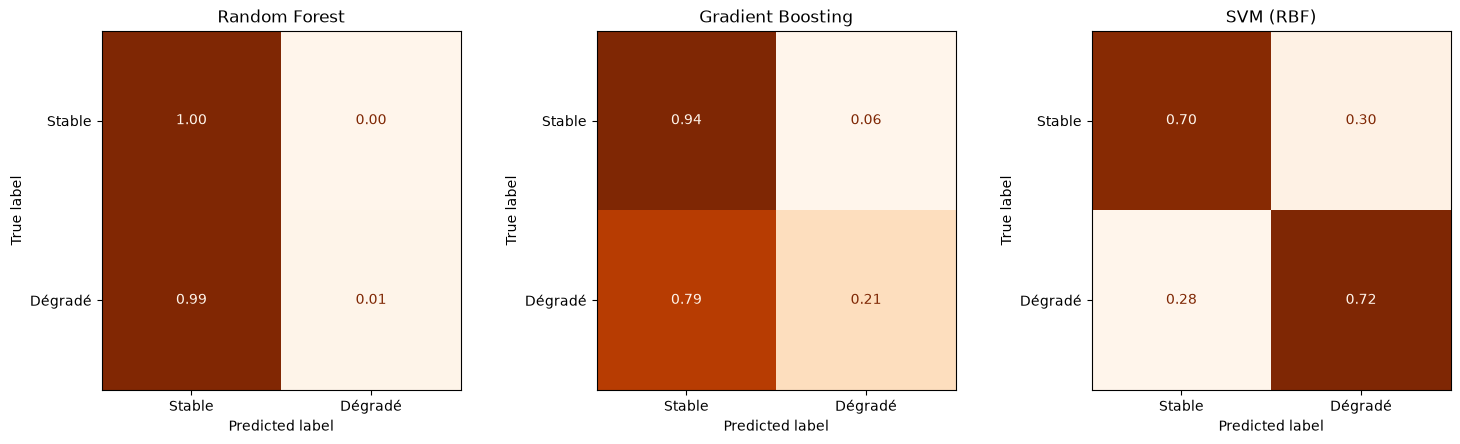

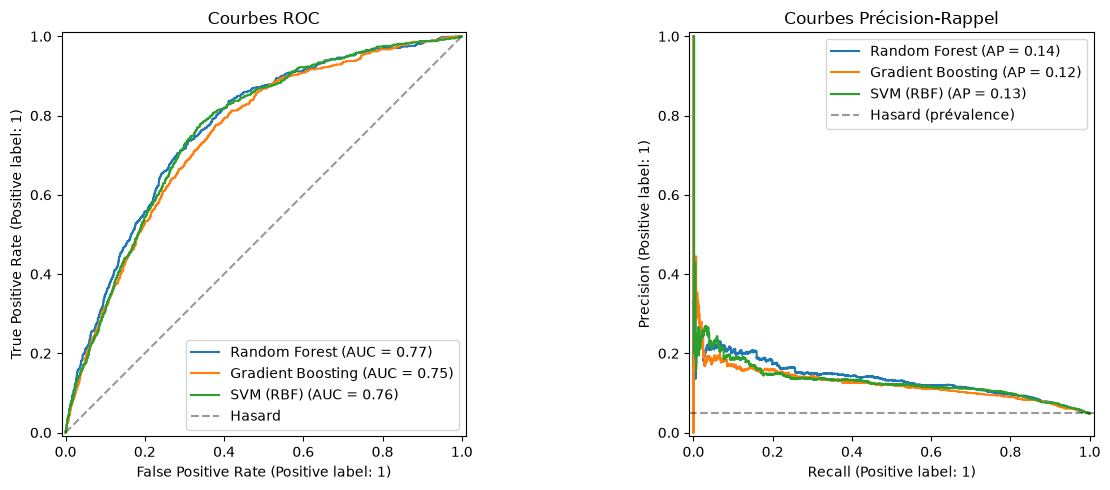

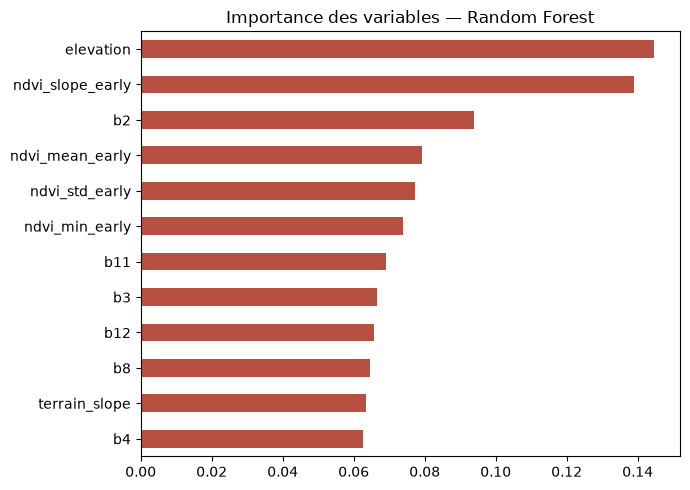

In [33]:
# Figures matrices de confusion (normalisées par ligne), courbes ROC et précision-rappel
# importance des variables du Random Forest (ajusté sur toutes les données)


from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

noms = list(MODELS.keys())

fig, axes = plt.subplots(1, len(noms), figsize=(5 * len(noms), 4.5))
for ax, nom in zip(axes, noms):
    ConfusionMatrixDisplay.from_predictions(
        y, preds[nom], normalize="true", display_labels=["Stable", "Dégradé"],
        cmap="Oranges", ax=ax, colorbar=False, values_format=".2f")
    ax.set_title(nom)
plt.tight_layout()
plt.savefig("../outputs/ml_confusion_matrices.png", dpi=150)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for nom in noms:
    RocCurveDisplay.from_predictions(y, scores[nom], name=nom, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y, scores[nom], name=nom, ax=ax2)
ax1.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Hasard")
ax1.set_title("Courbes ROC"); ax1.legend()
ax2.axhline(y.mean(), color="k", linestyle="--", alpha=0.4, label="Hasard (prévalence)")
ax2.set_title("Courbes Précision-Rappel"); ax2.legend()
plt.tight_layout()
plt.savefig("../outputs/ml_roc_pr_curves.png", dpi=150)
plt.show()

rf = clone(MODELS["Random Forest"]).fit(X, y)
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, color="#b85042")
ax.set_title("Importance des variables — Random Forest")
plt.tight_layout()
plt.savefig("../outputs/ml_feature_importance_rf.png", dpi=150)
plt.show()